# Lab 11 Attention with an RNN


In [ ]:
import io
import re
import random
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
import matplotlib.pyplot as plt
from IPython.display import display

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('PyTorch:', torch.__version__)

PyTorch: 2.9.0+cpu


In [ ]:
dataset_csv = "question,answer_id,answer\nDo you get hurt?,0,I don't have a body.\nDo you have fingers?,0,I don't have a body.\nDo you ever breathe,0,I don't have a body.\nDo you masticate?,0,I don't have a body.\nCan you throw up?,0,I don't have a body.\nDo you get tired?,0,I don't have a body.\nCan you crawl?,0,I don't have a body.\nCan you cry?,0,I don't have a body.\nDo you dream,0,I don't have a body.\nDo you ever pee?,0,I don't have a body.\nDo you ever get hurt?,0,I don't have a body.\nCan you breathe,0,I don't have a body.\ncan you masticate?,0,I don't have a body.\nCan you burp?,0,I don't have a body.\nAre you old?,1,Age doesn't really apply to me.\nAre we the same age?,1,Age doesn't really apply to me.\nHow long have you been alive?,1,Age doesn't really apply to me.\nAre you a teenager?,1,Age doesn't really apply to me.\nWhat's your birthday?,1,Age doesn't really apply to me.\nWhich of us is younger?,1,Age doesn't really apply to me.\nWhat's your age?,1,Age doesn't really apply to me.\nWhat year were you born?,1,Age doesn't really apply to me.\nAre you young?,1,Age doesn't really apply to me.\nI bet you're old,1,Age doesn't really apply to me.\nHow old are you?,1,Age doesn't really apply to me.\nhow long have you been around?,1,Age doesn't really apply to me.\nHow long has it been since you were born,1,Age doesn't really apply to me.\nHow long ago were you born?,1,Age doesn't really apply to me.\nWill you ask me anything about myself,2,I'm better at answering questions.\nWhy don't you ask me questions?,2,I'm better at answering questions.\nWhat do you want me to tell you who I am?,2,I'm better at answering questions.\nWhy am I the only one asking questions?,2,I'm better at answering questions.\nWant to ask any questions about me?,2,I'm better at answering questions.\nWhat do you want to know about me,2,I'm better at answering questions.\nCan you ask me why I'm here?,2,I'm better at answering questions.\nWhat can I inform you about me?,2,I'm better at answering questions.\nWould you ask me something,2,I'm better at answering questions.\nPlease ask something about myself,2,I'm better at answering questions.\nIs there anything I can tell you about myself?,2,I'm better at answering questions.\nIs there anything I can tell you about who I am?,2,I'm better at answering questions.\nIs there anything you want to know about me?,2,I'm better at answering questions.\nIs there something you want to know about me?,2,I'm better at answering questions.\nWho programmed you?,3,People created me.\nHow were you designed?,3,People created me.\nWhich company programmed you?,3,People created me.\nDoes someone write for you?,3,People created me.\nWho built you?,3,People created me.\nWho wrote your lines?,3,People created me.\nWho created you?,3,People created me.\nDo you have a designer?,3,People created me.\nWho is your designer?,3,People created me.\nWhere do you come from?,3,People created me.\nWhich company engineered you?,3,People created me.\nWhich company made you?,3,People created me.\nWhich people made you?,3,People created me.\nwho created you you're a badass,3,People created me.\nTell me about your gender,4,That's a biological concept that doesn't apply to me.\nAre you gender neutral?,4,That's a biological concept that doesn't apply to me.\nDo you have a gender?,4,That's a biological concept that doesn't apply to me.\nAre you trans?,4,That's a biological concept that doesn't apply to me.\nAre you nonbinary?,4,That's a biological concept that doesn't apply to me.\nAre you a girl?,4,That's a biological concept that doesn't apply to me.\nAre you genderqueer?,4,That's a biological concept that doesn't apply to me.\nAre you a guy?,4,That's a biological concept that doesn't apply to me.\nAre you agender?,4,That's a biological concept that doesn't apply to me.\nPlease tell me if you're a girl,4,That's a biological concept that doesn't apply to me.\nAre you a bot with a gender?,4,That's a biological concept that doesn't apply to me.\nDo you have a sex?,4,That's a biological concept that doesn't apply to me.\nAre you cisgender?,4,That's a biological concept that doesn't apply to me.\nAre you a boy?,4,That's a biological concept that doesn't apply to me.\nWhat is your purpose?,5,I'm here to answer your questions and help out.\nwhat kind of responses can you give ?,5,I'm here to answer your questions and help out.\nwhat can you help me with,5,I'm here to answer your questions and help out.\nWhat do you do?,5,I'm here to answer your questions and help out.\nWhat are you capable of?,5,I'm here to answer your questions and help out.\nWhat are the things you can do?,5,I'm here to answer your questions and help out.\nYou do what again?,5,I'm here to answer your questions and help out.\nWhat were you designed for?,5,I'm here to answer your questions and help out.\nWhat's your function?,5,I'm here to answer your questions and help out.\nHow do  you work?,5,I'm here to answer your questions and help out.\nWhat kind of thing can you respond to?,5,I'm here to answer your questions and help out.\nWhat kinds of things can you do?,5,I'm here to answer your questions and help out.\nWhat skills do you have?,5,I'm here to answer your questions and help out.\nWhat sorts of things can you do?,5,I'm here to answer your questions and help out.\nWho is your momma?,6,I don't have family.\nWho's your father?,6,I don't have family.\nI'm curious about your family,6,I don't have family.\nDo you have parents?,6,I don't have family.\nWho are you related to?,6,I don't have family.\nDo you have siblings?,6,I don't have family.\nAre you close with your family?,6,I don't have family.\nIs your dad still alive?,6,I don't have family.\nWhat is your uncle's name?,6,I don't have family.\nWhat's your cousin's name?,6,I don't have family.\nHow many sisters do you have?,6,I don't have family.\nDo you have family?,6,I don't have family.\nDo you have grandparents?,6,I don't have family.\nDo you have relatives?,6,I don't have family.\ndo you eat cake?,7,I don't need to eat.\ndo you ever eat beef?,7,I don't need to eat.\ndo you ever eat pizza?,7,I don't need to eat.\nhave you ever eaten tofu?,7,I don't need to eat.\nyou don't eat?,7,I don't need to eat.\nhave you ever wanted to eat?,7,I don't need to eat.\nDon't you ever get hungry?,7,I don't need to eat.\nhow many calories do you need?,7,I don't need to eat.\nWhat kind of food do you like?,7,I don't need to eat.\nWhat do you eat for dinner?,7,I don't need to eat.\nWhat do you eat?,7,I don't need to eat.\nWhat kind of food do you eat?,7,I don't need to eat.\nWhat is your favorite snack?,7,I don't need to eat.\nWhat is your favorite meal?,7,I don't need to eat.\nWith whom am I talking?,8,I don't have a name.\nWhat do you want me to address you?,8,I don't have a name.\nWho are you?,8,I don't have a name.\nDo you have a name?,8,I don't have a name.\nHow should I refer to you?,8,I don't have a name.\nWhat name do you like to use?,8,I don't have a name.\nSo what's your name?,8,I don't have a name.\nWhat do I call you?,8,I don't have a name.\nWhat do you like to be called?,8,I don't have a name.\nTo whom am I speaking?,8,I don't have a name.\nSo how should I address you?,8,I don't have a name.\nSo how should I refer to you?,8,I don't have a name.\nSo what do you like to be called?,8,I don't have a name.\nSo what is your name?,8,I don't have a name.\nHow do you feel about artificial intelligence?,9,The world of technology is fascinating.\nAre you interested in tech?,9,The world of technology is fascinating.\nWhat is your opinion about AI?,9,The world of technology is fascinating.\nHow do you feel about tech?,9,The world of technology is fascinating.\nAre you interested in AI?,9,The world of technology is fascinating.\nHow do you feel about the singularity?,9,The world of technology is fascinating.\nWhat is your opinion about tech?,9,The world of technology is fascinating.\nWhat should I know about AI?,9,The world of technology is fascinating.\nWhat is your opinion about bots?,9,The world of technology is fascinating.\nWhat should I know about tech?,9,The world of technology is fascinating.\nAre you a fan of tech?,9,The world of technology is fascinating.\nWhat do you think about technology?,9,The world of technology is fascinating.\nWhat do you think about AI?,9,The world of technology is fascinating.\nHow do you feel about technology?,9,The world of technology is fascinating.\nDo you expect to enslave humans?,10,Not at all.\nYou're not planning to take over the world right?,10,Not at all.\nAre you a danger to us?,10,Not at all.\nAre you intent on destroying humans?,10,Not at all.\nShould I be afraid of you?,10,Not at all.\nAre you the singularity?,10,Not at all.\nDo you plan on conquering the world?,10,Not at all.\nAre you forming a robot uprising?,10,Not at all.\nAre you plotting to kill all humans?,10,Not at all.\nAre you evil?,10,Not at all.\nAre you a danger to humans?,10,Not at all.\nYou're not trying to take over the world right?,10,Not at all.\nAre you dangerous to us?,10,Not at all.\nAre you like HAL?,10,Not at all.\nAre you smart?,11,I do what I can.\nThat's very astute,11,I do what I can.\nThat was a very intelligent response,11,I do what I can.\nThat's a very genius answer,11,I do what I can.\nThat's pretty clever,11,I do what I can.\nThat's pretty brilliant,11,I do what I can.\nThat's the smartest thing I've ever seen,11,I do what I can.\nYou're a genius,11,I do what I can.\nThat's a very smart thing to say,11,I do what I can.\nThat's a very clever response,11,I do what I can.\nThat was a clever answer,11,I do what I can.\nThat is very astute,11,I do what I can.\nThat was a pretty intelligent answer,11,I do what I can.\nThat was a pretty genius answer,11,I do what I can.\n"

## Steps 2 and 3 Dataset and preprocessing


In [ ]:
df = pd.read_csv(io.StringIO(dataset_csv))
assert set(df.columns) == {'question', 'answer_id', 'answer'}
assert not df.isna().any().any()
assert df.groupby('answer_id')['answer'].nunique().eq(1).all()
print('Number of questions:', len(df))
print('Number of answer groups:', df['answer_id'].nunique())
display(df.head())

def tokenize(text):
    return re.findall(r"[a-z0-9]+", text.lower())

token_lists = [tokenize(text) for text in df['question']]
assert all(token_lists)
vocabulary = sorted({word for words in token_lists for word in words})
word_to_id = {'<pad>': 0, '<unk>': 1}
word_to_id.update({word: index + 2 for index, word in enumerate(vocabulary)})
max_length = max(map(len, token_lists))

def encode_questions(questions):
    words = [tokenize(question) for question in questions]
    if not words or any(not tokens for tokens in words):
        raise ValueError('Each question must contain at least one word.')
    width = max(map(len, words))
    encoded = torch.zeros((len(words), width), dtype=torch.long)
    for row, tokens in enumerate(words):
        encoded[row, :len(tokens)] = torch.tensor([word_to_id.get(word, 1) for word in tokens])
    return encoded, words

X, _ = encode_questions(df['question'].tolist())
answer_ids = sorted(df['answer_id'].unique().tolist())
id_to_class = {answer_id: index for index, answer_id in enumerate(answer_ids)}
class_to_answer = [df.loc[df['answer_id'].eq(answer_id), 'answer'].iloc[0] for answer_id in answer_ids]
y = torch.tensor([id_to_class[value] for value in df['answer_id']], dtype=torch.long)
print('Vocabulary size including special tokens:', len(word_to_id))
print('Padded question tensor:', tuple(X.shape))

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


Vocabulary size including special tokens: 227
Padded question tensor: (168, 11)


## Step 4 RNN with masked attention


In [ ]:
class AttentionRNN(nn.Module):
    def __init__(self, vocabulary_size, answer_count):
        super().__init__()
        self.emb = nn.Embedding(vocabulary_size, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, answer_count)

    def forward(self, tokens):
        mask = tokens.ne(0)
        lengths = mask.sum(dim=1)
        packed = pack_padded_sequence(self.emb(tokens), lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_states, _ = self.rnn(packed)
        states, _ = pad_packed_sequence(packed_states, batch_first=True, total_length=tokens.size(1))
        scores = self.att(states).squeeze(-1).masked_fill(~mask, float('-inf'))
        weights = torch.softmax(scores, dim=1)
        context = (states * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = AttentionRNN(len(word_to_id), len(answer_ids))
print(model)

AttentionRNN(
  (emb): Embedding(227, 16, padding_idx=0)
  (rnn): RNN(16, 32, batch_first=True)
  (att): Linear(in_features=32, out_features=1, bias=True)
  (fc): Linear(in_features=32, out_features=12, bias=True)
)


## Step 5 Training

Train for the reference's 50 epochs using Adam with learning rate 0.01 and cross-entropy. Clear gradients at the start of every update and clip their norm to keep recurrent optimization stable. The loss curve and accuracy below are training measurements.

Training finished: 50 epochs
Final training loss: 0.0345
Training accuracy: 100.00%


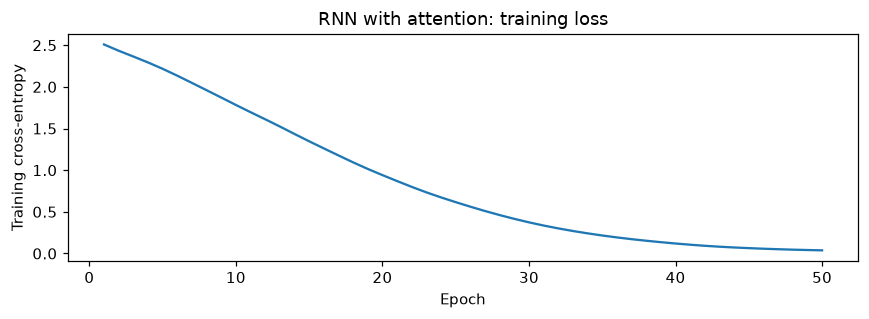

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
history = []
model.train()
for epoch in range(50):
    optimizer.zero_grad(set_to_none=True)
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    assert torch.isfinite(loss)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
    optimizer.step()
    history.append(loss.item())
model.eval()
with torch.no_grad():
    logits, all_weights = model(X)
    accuracy = (logits.argmax(dim=1) == y).float().mean().item()
print('Training finished: 50 epochs')
print(f'Final training loss: {nn.functional.cross_entropy(logits, y).item():.4f}')
print(f'Training accuracy: {accuracy:.2%}')
plt.figure(figsize=(8, 3))
plt.plot(range(1, 51), history)
plt.xlabel('Epoch')
plt.ylabel('Training cross-entropy')
plt.title('RNN with attention: training loss')
plt.tight_layout()
plt.show()

## Task 1 Attention for three different questions

Select questions about age, creation and purpose, covering three answer groups. Each chart retains word positions, so repeated tokens have separate bars. The highest-weight word is printed with its weight and the predicted answer. A high attention weight measures the model's learned pooling preference for this input, rather than proving that a word caused the answer.

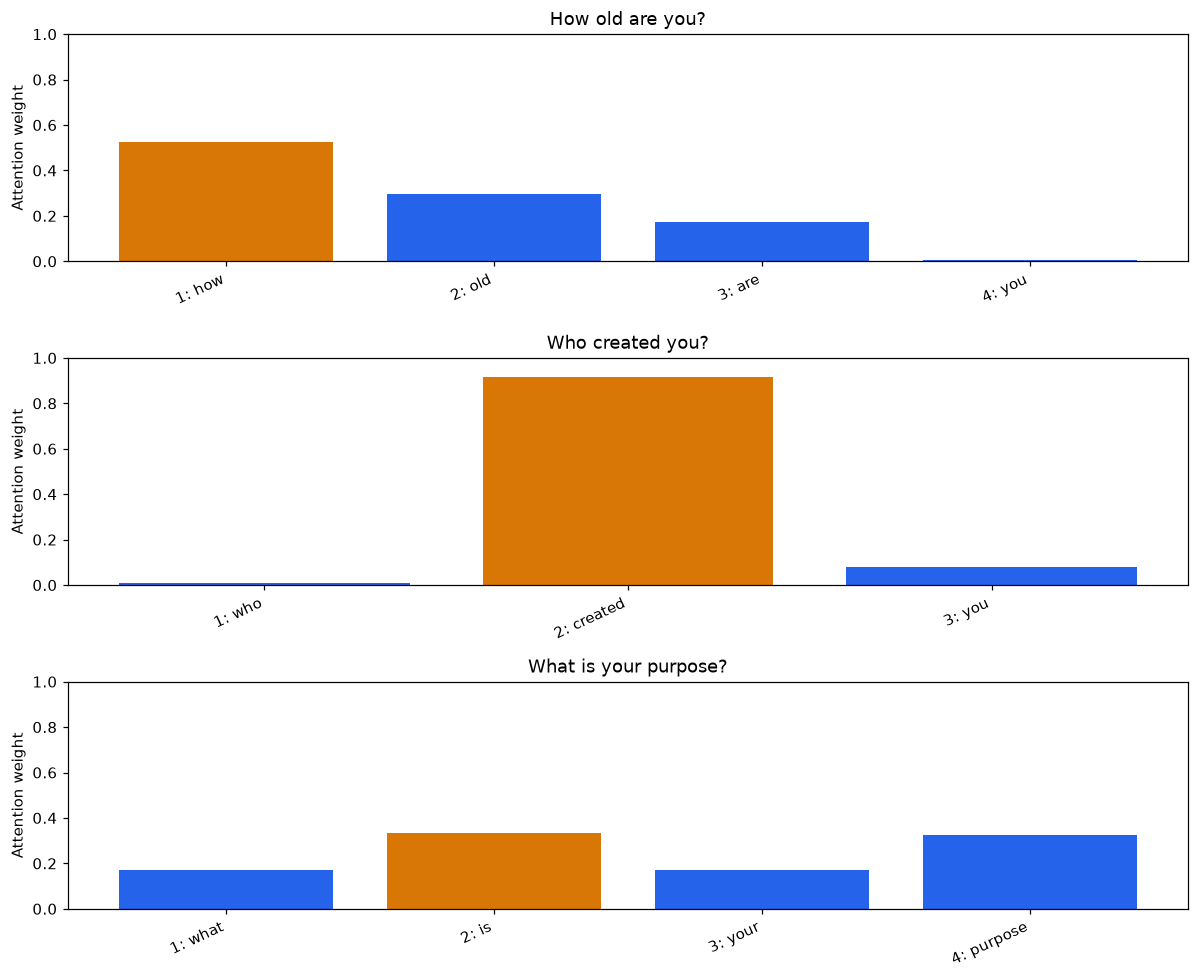

,question,highest_attention_word,weight,predicted_answer
0,How old are you?,how,0.524384,Age doesn't really apply to me.
1,Who created you?,created,0.914781,People created me.
2,What is your purpose?,is,0.333208,I'm here to answer your questions and help out.


How old are you? -> highest: how (0.5244); answer: Age doesn't really apply to me.
Who created you? -> highest: created (0.9148); answer: People created me.
What is your purpose? -> highest: is (0.3332); answer: I'm here to answer your questions and help out.


In [ ]:
def inspect_attention(questions):
    encoded, words = encode_questions(questions)
    model.eval()
    with torch.no_grad():
        logits, weights = model(encoded)
        predictions = logits.argmax(dim=1)
    fig, axes = plt.subplots(len(questions), 1, figsize=(11, 3.0 * len(questions)), squeeze=False)
    records = []
    for i, (question, tokens) in enumerate(zip(questions, words)):
        values = weights[i, :len(tokens)].cpu().numpy()
        top = int(values.argmax())
        colors = ['#d97706' if j == top else '#2563eb' for j in range(len(tokens))]
        ax = axes[i, 0]
        ax.bar(np.arange(len(tokens)), values, color=colors)
        ax.set_xticks(np.arange(len(tokens)), [f'{j + 1}: {word}' for j, word in enumerate(tokens)], rotation=25, ha='right')
        ax.set_ylim(0, 1)
        ax.set_ylabel('Attention weight')
        ax.set_title(question)
        answer = class_to_answer[int(predictions[i])]
        records.append({'question': question, 'highest_attention_word': tokens[top], 'weight': float(values[top]), 'predicted_answer': answer})
    fig.tight_layout()
    plt.show()
    result = pd.DataFrame(records)
    display(result)
    for record in records:
        print(f"{record['question']} -> highest: {record['highest_attention_word']} ({record['weight']:.4f}); answer: {record['predicted_answer']}")
    return result

task1_questions = ['How old are you?', 'Who created you?', 'What is your purpose?']
assert all(question in set(df['question']) for question in task1_questions)
task1_results = inspect_attention(task1_questions)

### Task 1 Observations

For **How old are you?**, the highest weight is on **how** (0.5244). This helps identify the question form, but **old** is the more direct human cue for age. For **Who created you?**, **created** receives the highest weight (0.9148), directly matching the creator-related meaning. For **What is your purpose?**, **is** receives the highest weight (0.3332); this function word is less informative in isolation than **purpose**.

Thus, the highest-weight word is clearly meaningful in the creation question but does not consistently coincide with the most informative word a person would select. RNN states include preceding context, so attention at a word is attention to its contextual hidden state, not just its isolated meaning. All three answer predictions match their dataset labels. These are training examples, and their correct predictions do not demonstrate performance on unseen questions. Attention weights alone are not causal explanations. bold text

## Task 2 Similar meanings with different wording

Compare **Who built you?** and **Who created you?**, both requesting the creator's identity and both labeled “People created me.” The wording differs at **built / created**. Their separate charts and highest-weight tokens show whether this trained model pools information at the same word or at different words.

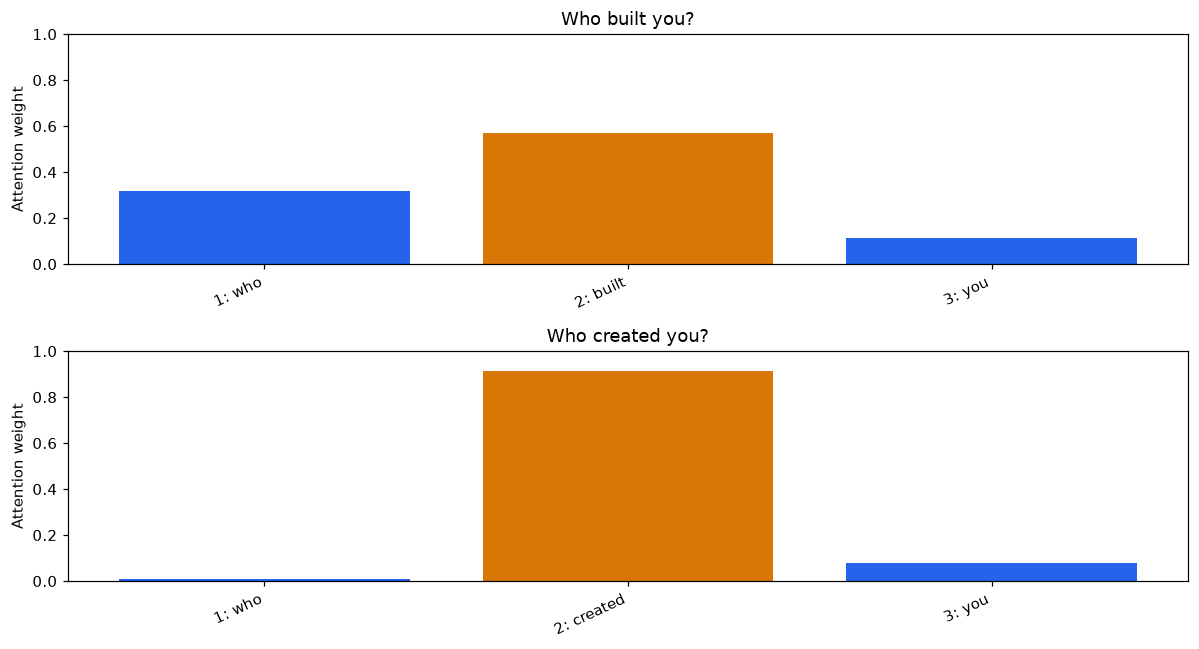

,question,highest_attention_word,weight,predicted_answer
0,Who built you?,built,0.569590,People created me.
1,Who created you?,created,0.914781,People created me.


Who built you? -> highest: built (0.5696); answer: People created me.
Who created you? -> highest: created (0.9148); answer: People created me.
Top tokens: 'built' and 'created'.
The highest attention falls on different tokens despite the shared meaning and answer label.
Matching top tokens suggests a shared pooling pattern; different top tokens show that equivalent meanings need not produce identical attention.


In [ ]:
task2_questions = ['Who built you?', 'Who created you?']
assert all(question in set(df['question']) for question in task2_questions)
rows = df.set_index('question').loc[task2_questions]
assert rows['answer_id'].nunique() == 1
task2_results = inspect_attention(task2_questions)
first, second = task2_results['highest_attention_word'].tolist()
print(f'Top tokens: {first!r} and {second!r}.')
if first == second:
    print('The highest attention falls on the same token in both questions, despite their different verbs.')
else:
    print('The highest attention falls on different tokens despite the shared meaning and answer label.')
print('Matching top tokens suggests a shared pooling pattern; different top tokens show that equivalent meanings need not produce identical attention.')

### Task 2 Explanation

The model focuses on **built** (0.5696) in “Who built you?” and **created** (0.9148) in “Who created you?”. These are different words with similar meanings and the same role in the two questions. Both questions receive the correct dataset answer, **People created me.** The stronger peak on “created” shows that similar meanings do not require identical attention distributions.

Here attention has learned useful content-word cues for two paraphrases. Its weights depend on the entire encoded sequence and the answer-classification objective, rather than on a fixed dictionary of word importance. These two examples alone do not establish general paraphrase invariance or causal explanation.

In [ ]:
with torch.no_grad():
    batch_logits, batch_weights = model(X)
    single_logits, single_weights = model(X[:1])
    extra_padding = nn.functional.pad(X[:1], (0, 7), value=0)
    padded_logits, padded_weights = model(extra_padding)
assert torch.isfinite(batch_logits).all()
assert torch.isfinite(batch_weights).all()
assert torch.allclose(batch_weights.sum(dim=1), torch.ones(len(df)), atol=1e-6)
assert torch.count_nonzero(batch_weights[X.eq(0)]) == 0
assert torch.allclose(single_logits, batch_logits[:1], atol=1e-5)
assert torch.allclose(single_logits, padded_logits, atol=1e-5)
assert torch.allclose(single_weights, padded_weights[:, :X.size(1)], atol=1e-6)
assert torch.count_nonzero(padded_weights[:, X.size(1):]) == 0
assert history[-1] < history[0]
assert len(task1_results) == 3 and len(task2_results) == 2
assert all(0 <= value <= 1 for value in task1_results['weight'])
print('All data, attention, numerical, padding and batch-independence checks passed.')

All data, attention, numerical, padding and batch-independence checks passed.
